We need a quick way to import our lightcurves, clean them a bit, then detect any flares. The point of this notebook isnt to get super precise flare rates, we can do that later. The idea is just to get some simple statistics out with minimal effort.

In [5]:
%matplotlib widget
import lightkurve as lk
import matplotlib.pyplot as plt
import numpy as np
from astropy.table import Table
import re
import glob
from ipywidgets import Dropdown
from IPython.display import display

# DOWNLOADING THE LIGHTCURVES 

First, lets get our list of sources in. Here, we only want to keep sources that we know we have data for. Lightcurves where we don't have radio data have no (current) use to us.

In [4]:
sources = Table.read('data/source_obs_data.csv')

In [21]:
detected_mask = sources['n_obs'] > 0
source_names_raw = sources[detected_mask]['Simbad_ID'].tolist()

Next, we need to make sure our names are formatted correctly. Sometimes Simbad adds extra spaces (for some reason) so we just replace any additional whitespace with a single space so that lightkurve can interpret our source names. We also make a file name friendly version of our names so we can save our lightcurves under their Simbad IDs instead of their TIC IDs to save me the headache of remembering 2 numbers per star.

In [31]:
source_names = [re.sub(r"\s+", " ", src_raw).strip() for src_raw in source_names_raw]

In [32]:
fnames = [re.sub(r'[^a-z0-9_-]', '', source_name.lower().replace(" ", "_")) for source_name in source_names]

Finally, since we have a list of targets, we can (hopefully) just download and save their lightcurves directly to a folder, which we can read from later.

In [42]:
def lc_to_table(lc, src): # Just used so we can save it in a FITS format and retain the metadata that the LK object wasn't letting me do
    
    # Create the table
    t = Table()

    # Values I want to keep
    t['time'] = lc.time.value
    t['flux'] = lc.flux
    t['flux_err'] = lc.flux_err

    # Metadata I want to keep
    t.meta['sbid'] = src
    t.meta['ticid'] = lc.TICID

    return t

In [43]:
for src in source_names:
    
    # Search for our lightcurve
    lc_list = lk.search_lightcurve(src, author='QLP')
    
    if len(lc_list) > 0:
        
        # Stitch the lc together
        lc = lc_list.download_all().stitch()

        # Conver to a table
        t = lc_to_table(lc, src)

        # Create a filename that doesn't break
        fname = re.sub(r'[^a-z0-9_-]', '', src.lower().replace(" ", "_"))

        # Save the table
        t.write(f'tess_lightcurves/{fname}.fits', overwrite=True)
        
        print(f'Saved lightcurve for {src}')
    
    else: # Just in case something goes wrong
        print(f'No lightcurve found for {src}')

Saved lightcurve for HD 102982
Saved lightcurve for HD 82533


/suphys/jfer9940/miniconda3/envs/dstools_env/lib/python3.11/site-packages/lightkurve/lightcurve.py:1154: LightkurveWarning: The light curve appears to be zero-centered (median=1.00e+00 +/- 2.25e+00); `normalize()` will divide the light curve by a value close to zero, which is probably not what you want.
  warnings.warn(


Saved lightcurve for HD 217344
Saved lightcurve for HD 8558
Saved lightcurve for HD 200244
Saved lightcurve for HD 162186
Saved lightcurve for BD+21 20A
Saved lightcurve for CPD-55 1885
Saved lightcurve for HD 13183
Saved lightcurve for HD 175897
Saved lightcurve for HD 22213
Saved lightcurve for V* AI Lep
Saved lightcurve for BD+09 4984B
Saved lightcurve for V* TY Col
Saved lightcurve for TYC 9143-577-1
Saved lightcurve for TYC 8927-1888-1
Saved lightcurve for CD-54 2499
Saved lightcurve for ASAS J091509-5700.4
Saved lightcurve for CD-31 8535
Saved lightcurve for CD-48 2972
Saved lightcurve for TYC 8135-2027-1
Saved lightcurve for TYC 7624-1094-1
Saved lightcurve for CD-75 652
Saved lightcurve for HD 205297
Saved lightcurve for HD 202917
Saved lightcurve for HD 220492
Saved lightcurve for HD 52118


Now we should have a complete set of lightcurves

# READING IN LIGHTCURVES

Since our lightcurves are saved, we can just read them in every time from our folder.

In [2]:
files = glob.glob("tess_lightcurves/*.fits")

lcs = []
for f in files:
    t = Table.read(f)
    
    lc = lk.LightCurve(
        time=t['time'],
        flux=t['flux'],
        flux_err=t['flux_err']
    )
    
    # restore metadata
    lc.meta['sbid'] = t.meta.get('SBID', None)
    lc.meta['ticid'] = t.meta.get('TICID', None)
    
    lcs.append(lc)

Now that we have our lightcurves, we can start making plots.

# LIGHTCURVE VISUALISATION WIDGET

Let's take a quick look at them before we do any flare detection stuff, just to get an idea of what our data is like.

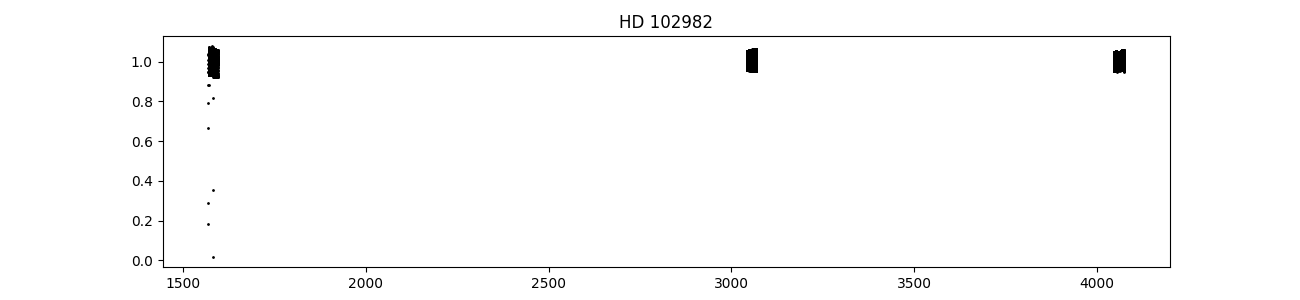

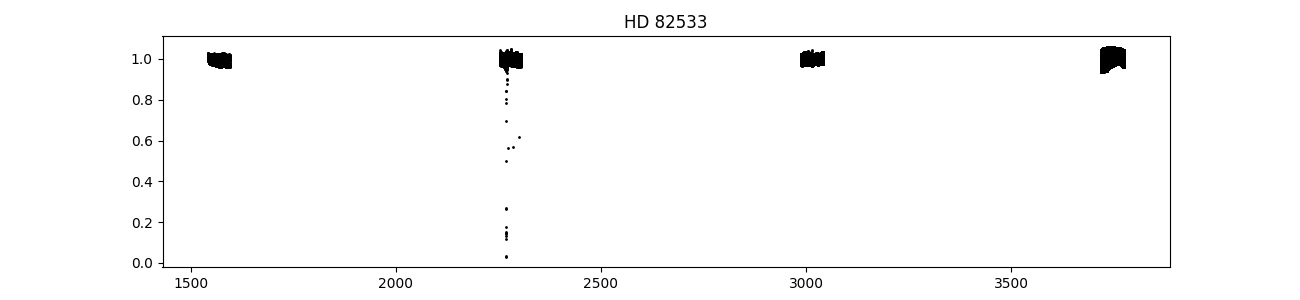

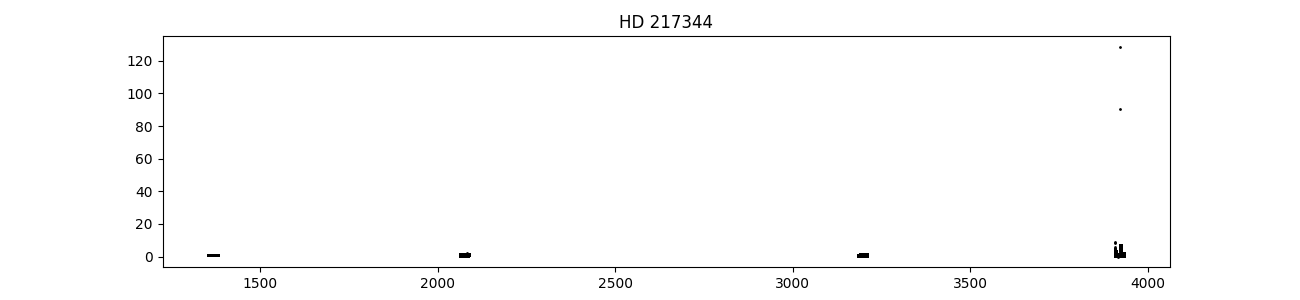

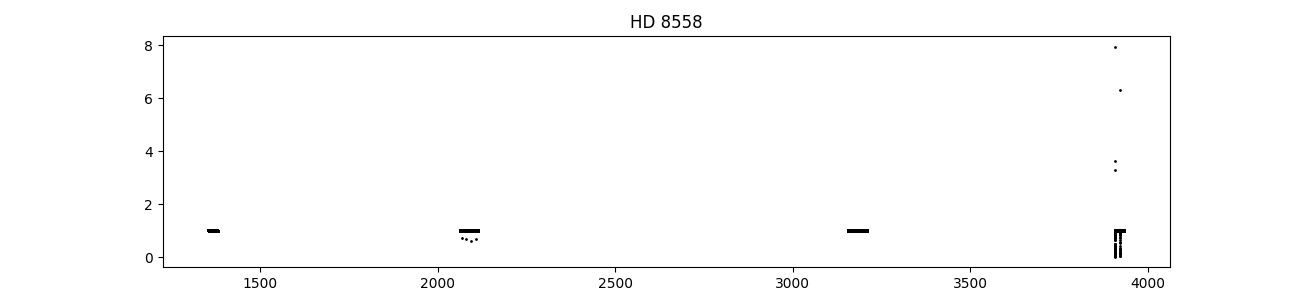

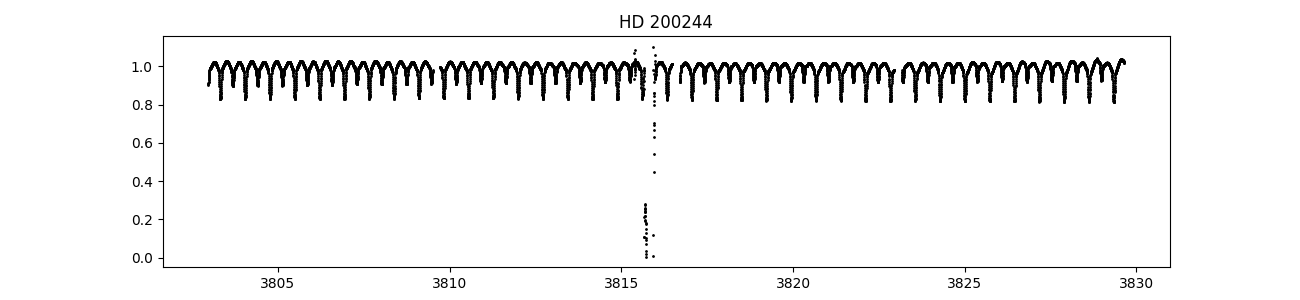

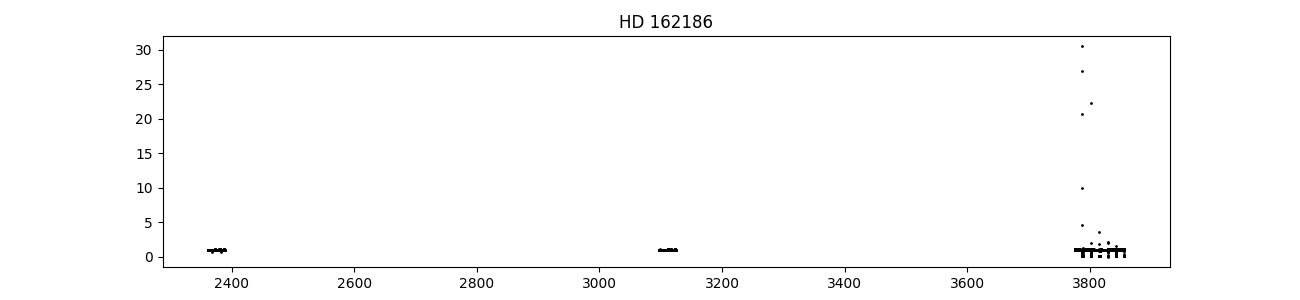

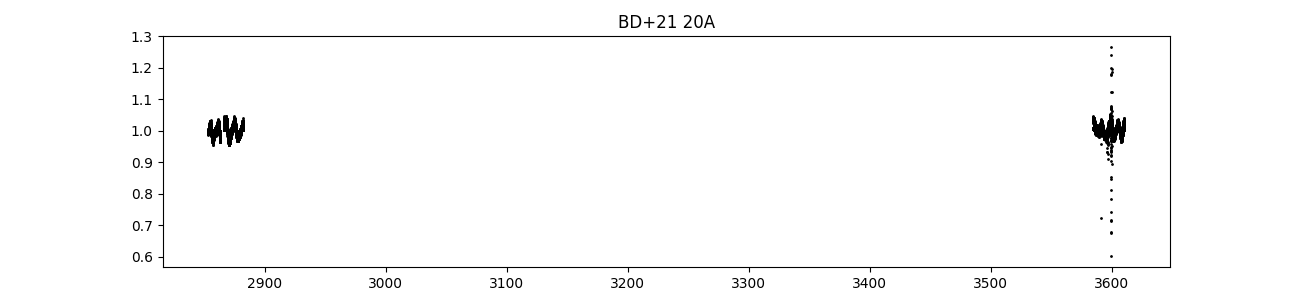

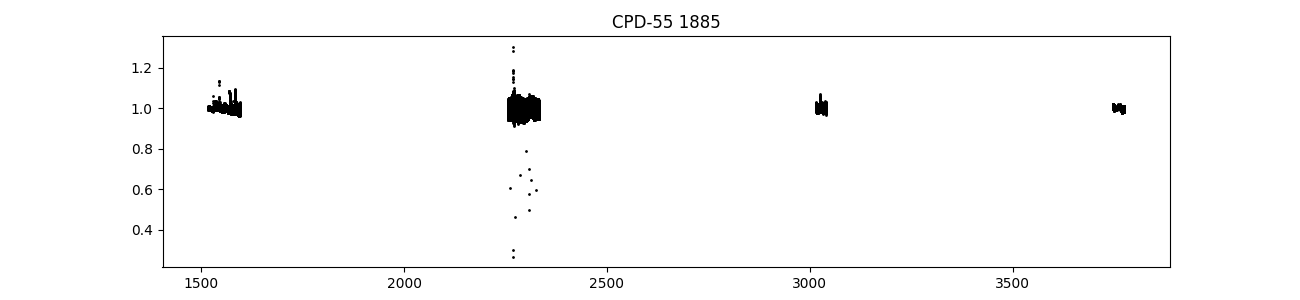

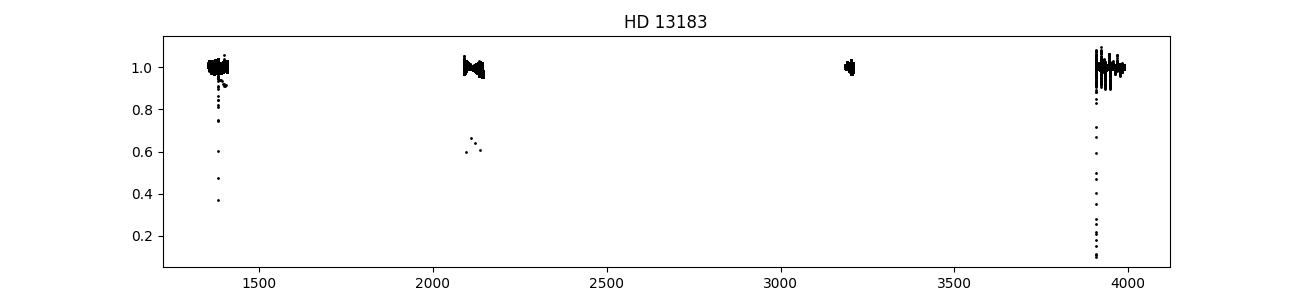

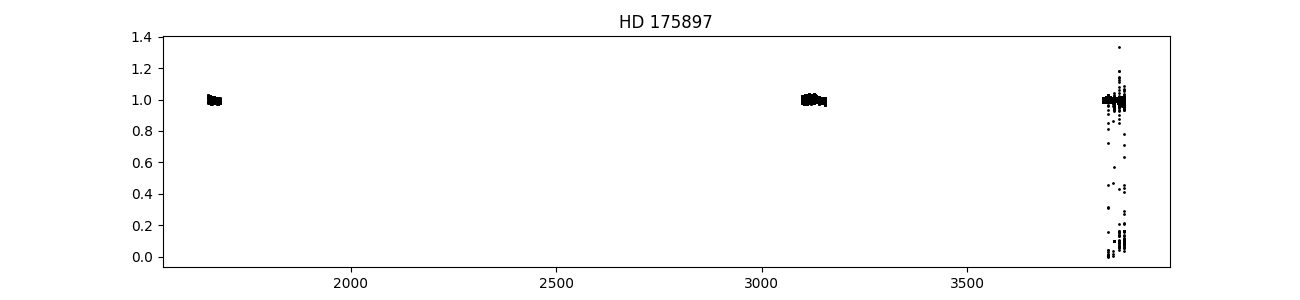

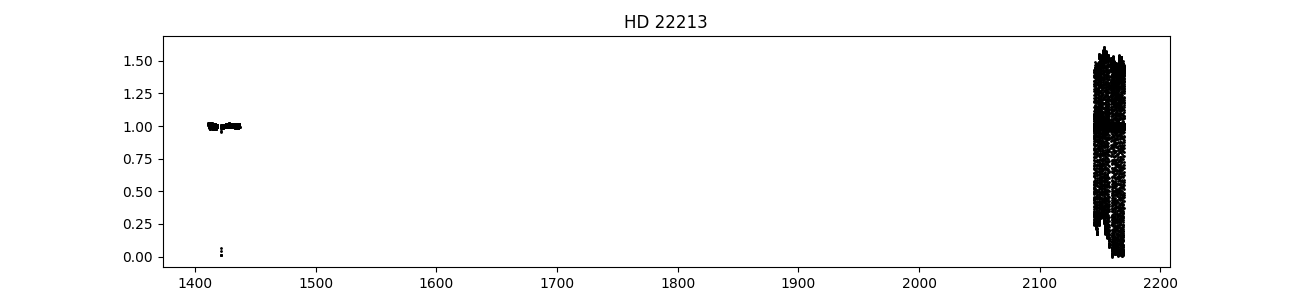

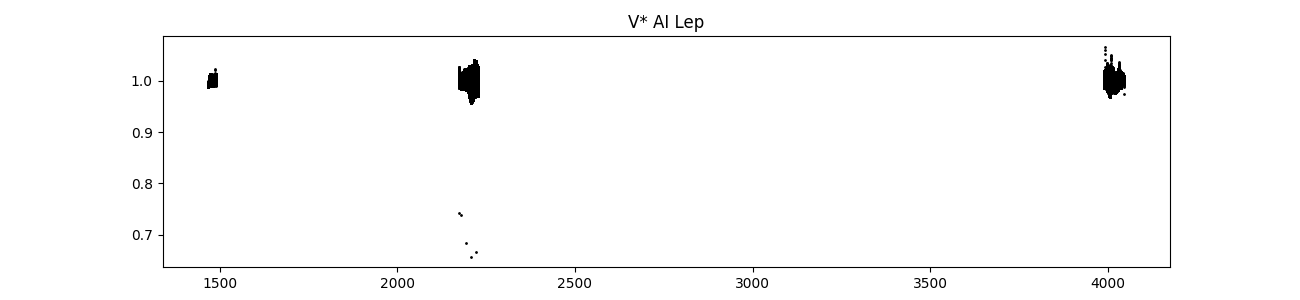

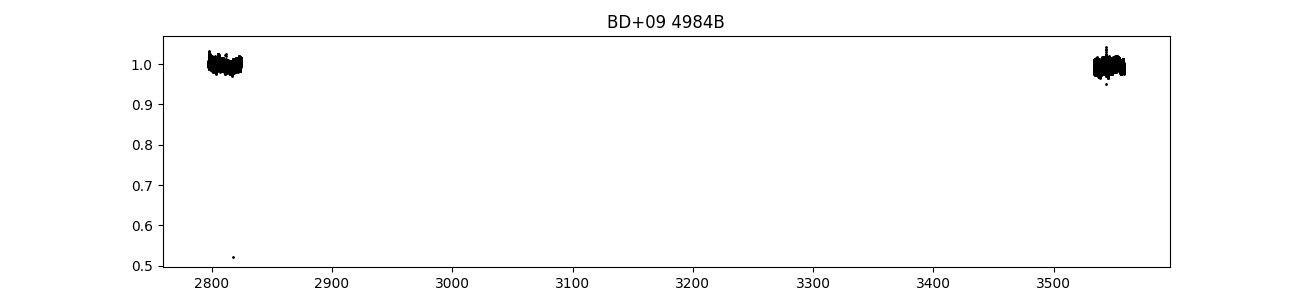

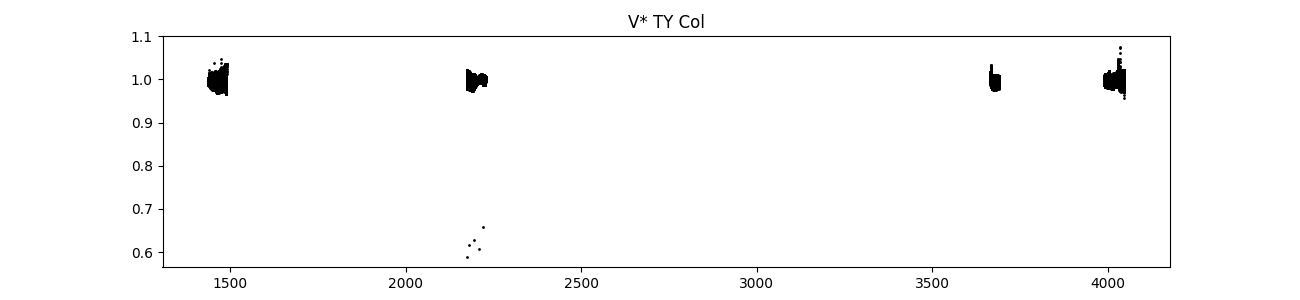

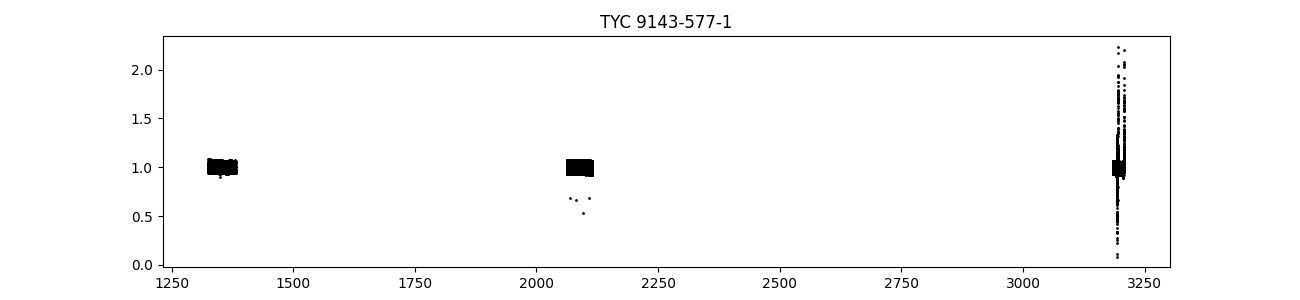

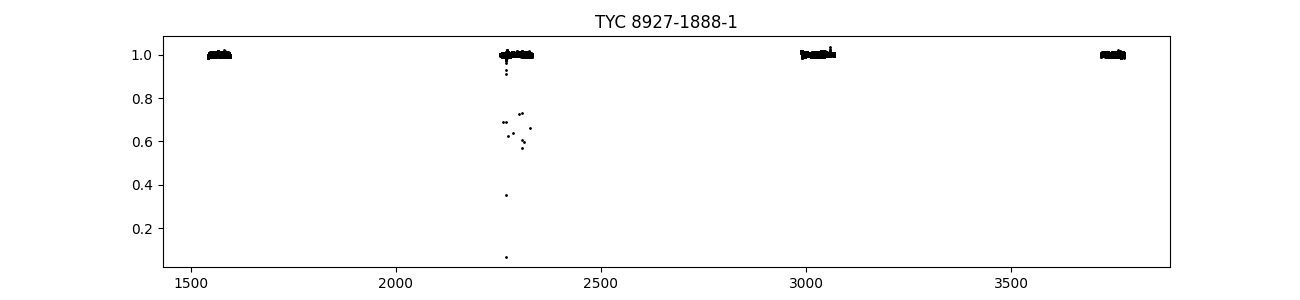

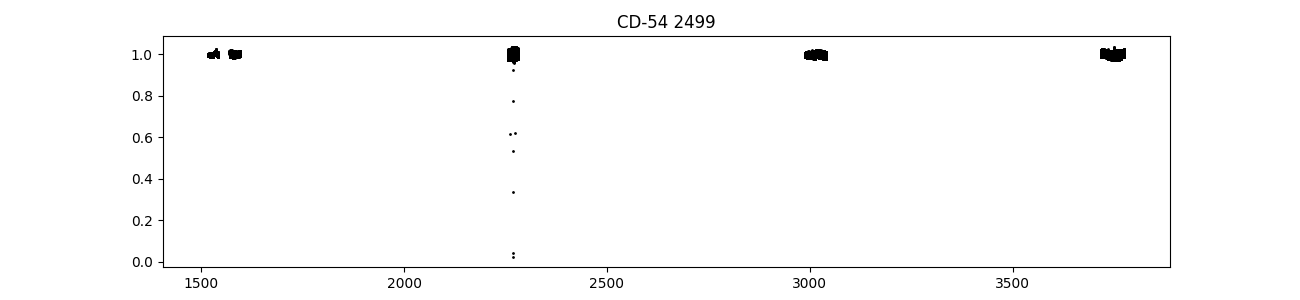

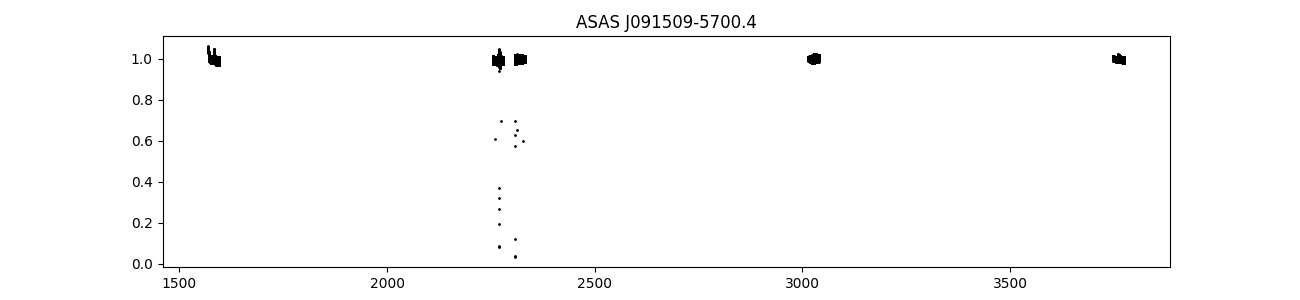

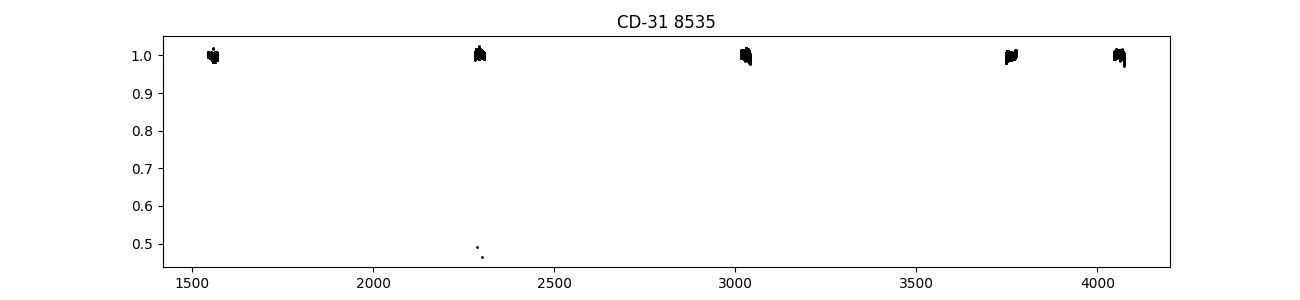

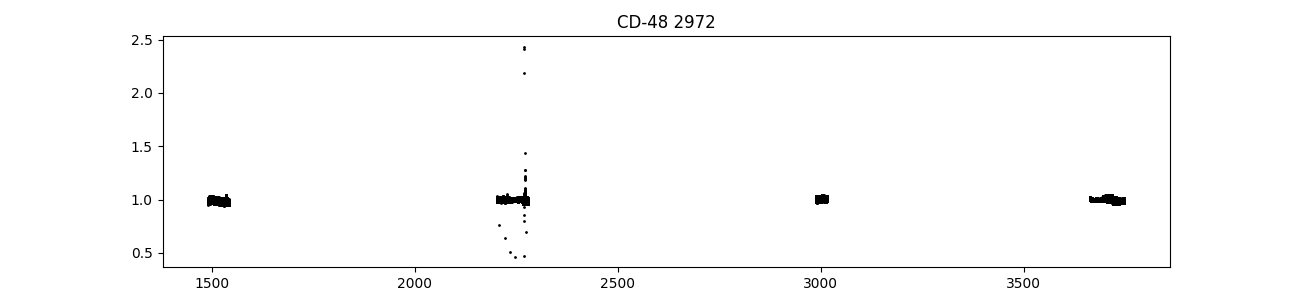

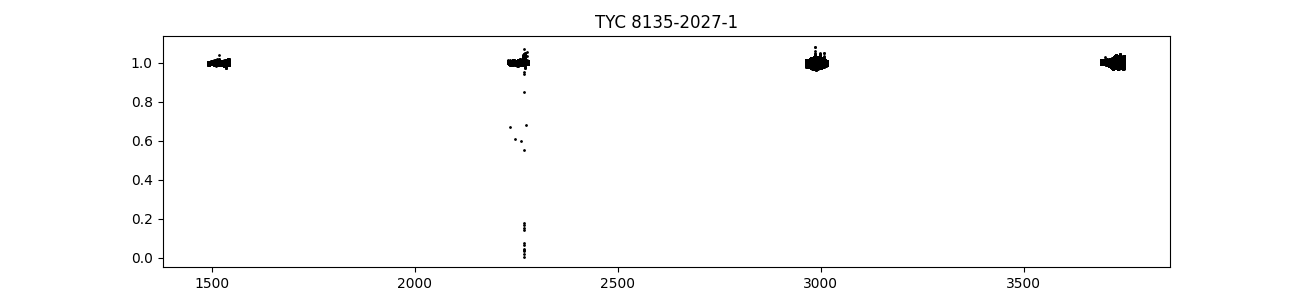

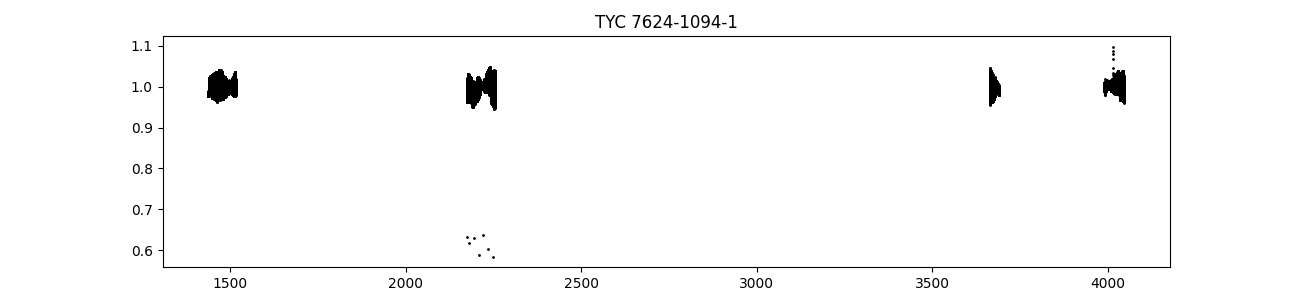

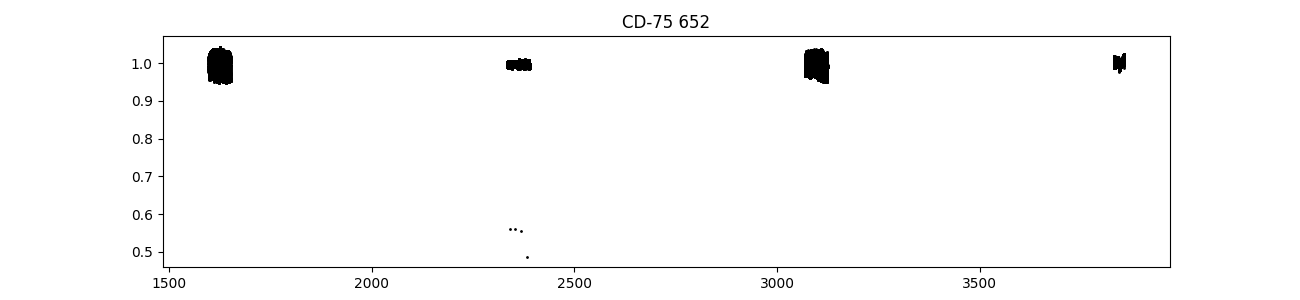

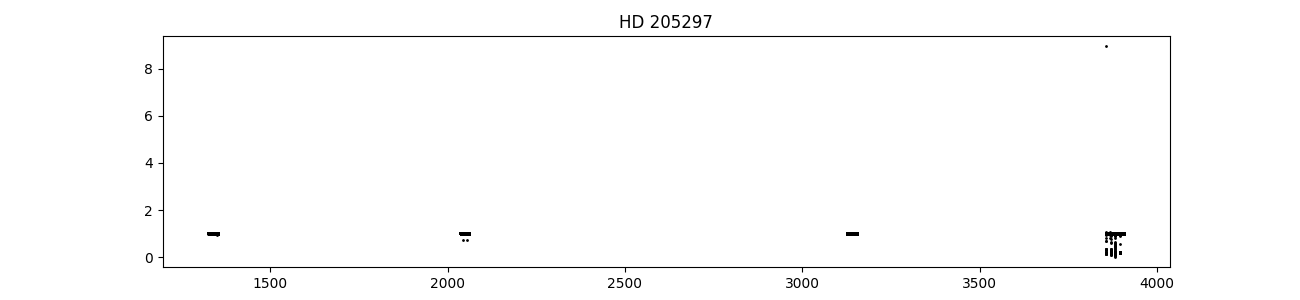

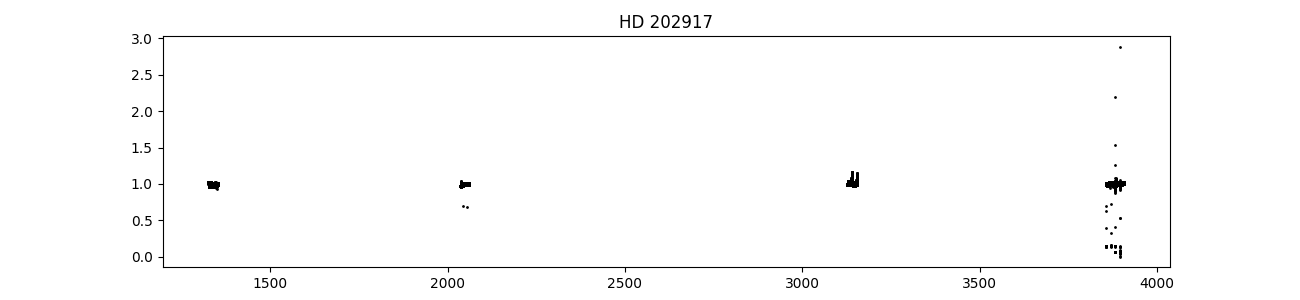

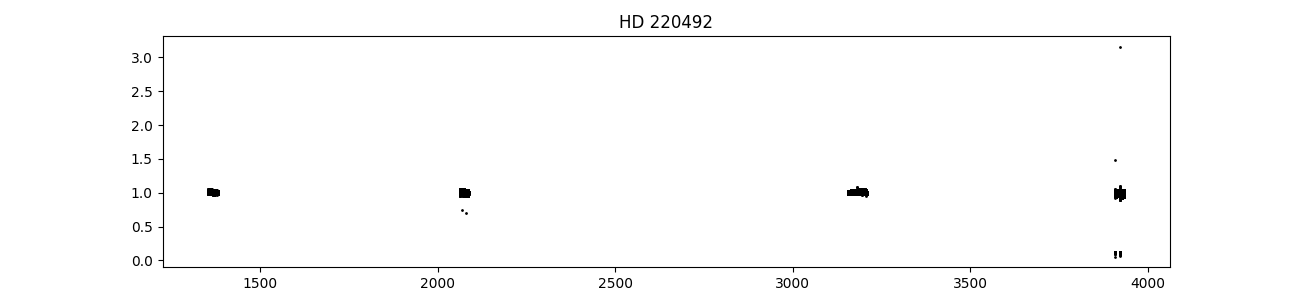

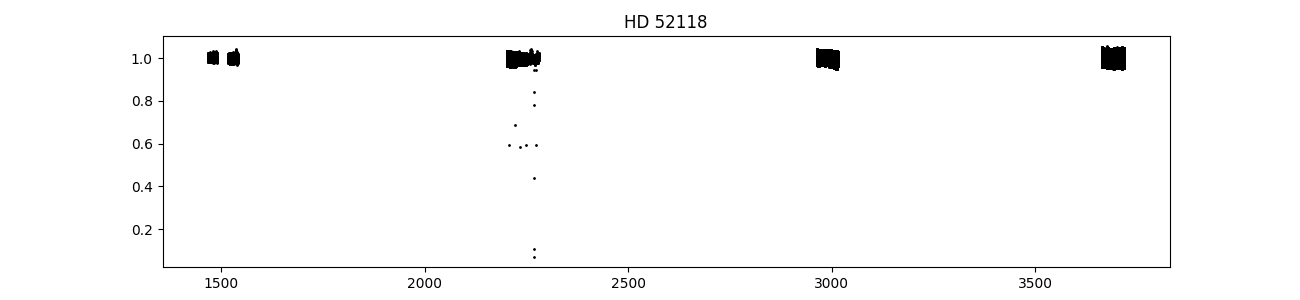

In [4]:
for lc in lcs:

    plt.figure(figsize = (13,3))
    plt.scatter(lc.time.value, lc.flux.value, c = 'black', s = 1)
    plt.title(lc.sbid)
    plt.show()
    plt.close()

This is a good first test, however clearly there still needs to be some work done on these lightcurves before we can start processing flares on them. Let's start by masking out data we clearly do not want to keep. We are only interested in flares, so deep eclipses can safely be cut. Likewise, any extreme outliers can also be cut.

Dropdown(description='Select LC:', options=('HD 102982', 'HD 82533', 'HD 217344', 'HD 8558', 'HD 200244', 'HD …

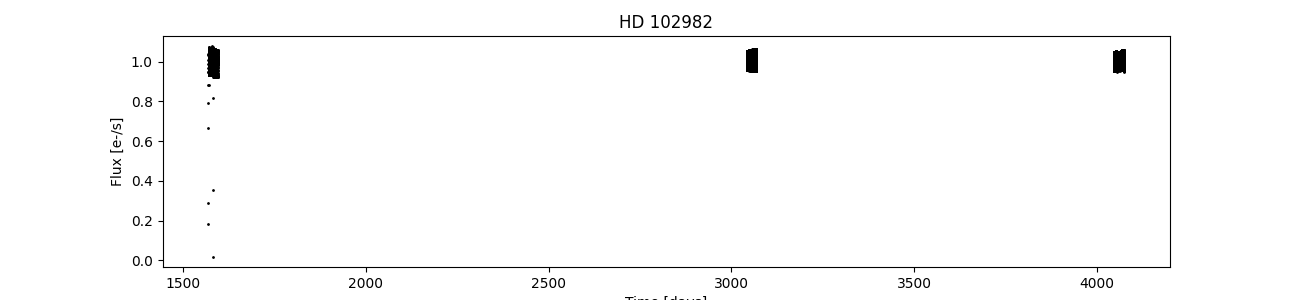

In [6]:
# Create a mapping for the dropdown: display name -> lc object
lc_dict = {str(lc.sbid): lc for lc in lcs}  # or any other string for names

# Create dropdown widget
dropdown = Dropdown(
    options=list(lc_dict.keys()),
    description='Select LC:'
)

# Create a figure once
fig, ax = plt.subplots(figsize=(13,3))

# Callback to update plot
def update_plot(change):
    ax.clear()
    lc = lc_dict[dropdown.value]
    ax.scatter(lc.time.value, lc.flux.value, c='black', s=1)
    ax.set_title(str(lc.sbid))
    ax.set_xlabel('Time [days]')
    ax.set_ylabel('Flux [e-/s]')
    fig.canvas.draw_idle()  # update the interactive figure

# Link the dropdown to the callback
dropdown.observe(update_plot, names='value')

# Display the dropdown
display(dropdown)

# Initial plot
update_plot(None)

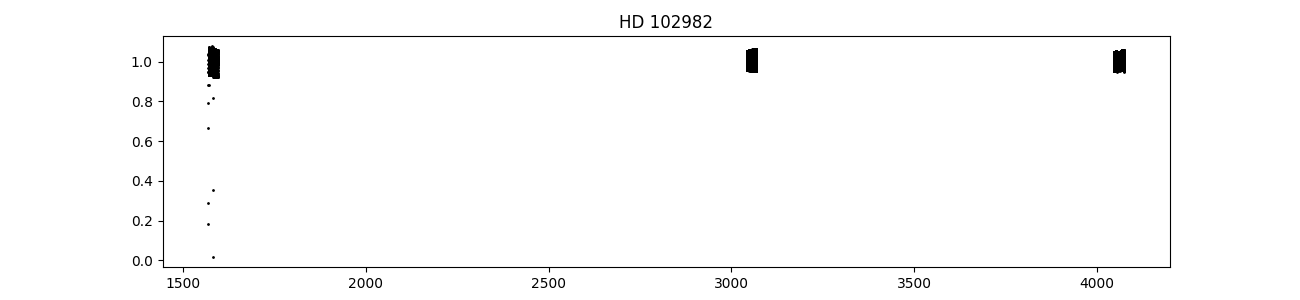

In [9]:
%matplotlib widget
lc = lcs[0]

plt.figure(figsize = (13,3))
plt.scatter(lc.time.value, lc.flux.value, c = 'black', s = 1)
plt.title(lc.sbid)
plt.show()

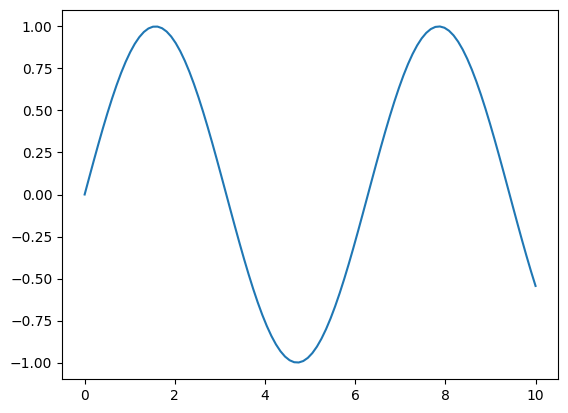

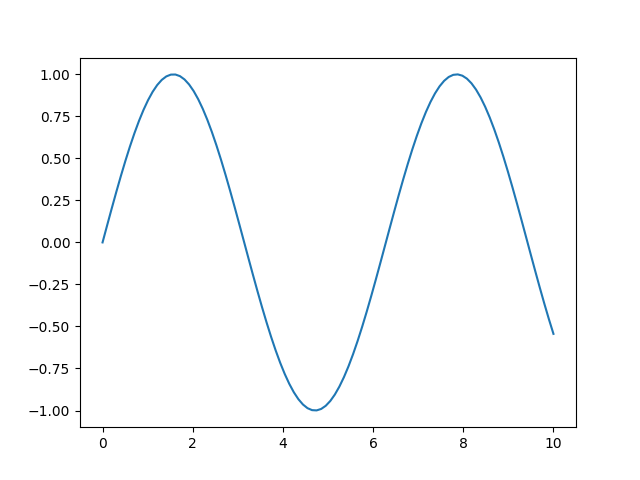

In [1]:
%matplotlib widget
import matplotlib.pyplot as plt
import numpy as np

fig, ax = plt.subplots()
x = np.linspace(0, 10, 100)
y = np.sin(x)
ax.plot(x, y)
fig  # <--- just leave this at the end, do NOT plt.show() or plt.close()